<H1>RNG</H1> 
Use a single qubit (or multiples) to create a series of random numbers. Going to try out a number of ideas. <br> 

Initially producing a number of random numbers that are <b>16 bit in length.</b> This is done by issuing a number of
measurements/shots (16 x N-Number) long. These bits are then divided up into individual 16 bit strings that
are then converted into numbers to be consumed. 
<ol>
    <li> just sample a series of qubits without initialization</li>
    <li> initalize to ground state and allow $T_2$ (shorter than $T_1$) to evolve, ie do a Hadamard then a X or Y rotation</li>
</ol>
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 20-Aug-25 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
    <tr> 
        <td> 11-Nov-26 </td>
        <td> CBL </td> 
        <td> Tuned up some comments and added in UDP/OSC connection.  </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href="https://docs.quantum.ibm.com/guides/install-qiskit"> Install Qikit </a> <br> 
<a href="https://docs.quantum.ibm.com/guides/hello-world"> qiskit hello world </a> <br> 
<a href="https://qiskit-community.github.io/qiskit-dynamics/"> Qiskit dynamics</a> <br> 
<a href="https://pypi.org/project/qiskit/"> Pypi qiskit page</a> <br> 
<a href="https://docs.quantum.ibm.com/api/qiskit/visualization"> Visualization</a> <br> 

<H3> OSC/UDP interface </H3>
<a href="https://docs.cycling74.com/legacy/max5/refpages/max-ref/udpreceive.html"> MAX/MSP UDP </a> <br> 
<a href="https://python-osc.readthedocs.io/en/latest/"> python OSC documentation </a>
<a href="https://python-osc.readthedocs.io/en/latest/client.html#module-pythonosc.udp_client"> example UDP client</a>

Make sure you have the python interface

pip install python_osc

<hr>
<H2> Notes </H2>
Hit every cell in order to get this to work. I may be overloaded on imports. This was a first pass. <br> 
If you want to run this on a real processor, you need to apply for an account and get a token. <br> 
This example uses the AER simulator package. <br> 
I am using the sampler rather than the estimator in this case. The estimator returns individual expection values. The sampler will return the value of each shot. 

<br> 

In [1]:
# my standard includes
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.constants as const
# Qiskit imports
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit.quantum_info import SparsePauliOp
from qiskit.quantum_info import Pauli
from scipy.spatial.transform import Rotation as R

import struct

# OSC/UDP stuff
from pythonosc import dispatcher, osc_server
from pythonosc.udp_client import SimpleUDPClient

# system call
import time

<H2> Define some helper functions. </H2>

In [2]:
def bit2N(s):
    """
    helper function, create a number of arbitrary length depending on input list. 
    @param s - input string, need 8 input bits to produce one byte
    """
    rv = 0
    for i in range(len(s)):
        rv = rv + s[i] * np.power(2,i)
    return rv[0]

<H2> Class to manage the OSC exchange</H2>
I've got several things I'm setting up here. The method generic send, just sends over the random number
without any prefix other than /QRNG. 

You can kind of see how I'm building a larger vocabulary here. There is a decision by the artist that needs
to be made, where are you going to do the heavy lifting, here or in the consumer (MAX/MSP or Touch Designer or any 
other OSC consumer.) My preference is here since I'm very comfortable with Python and Jupyter. I will build in
an event loop that is just here AND I will also setup a way to accept messages from the OSC consumer. 

Simple Vocabulary:

<ul>
    <li> /OSCnumber [Frequency, Phase] - send a frequency phase pair to the oscillator number.</li>
    <li> /QRNG value - just send a raw random number. </li>
</ul>
There is a companion set of patches, programs or whatever is the name that go with this. The
MAX/MSP one is called UDP5 and has examples of how I parse the messages. 

In [3]:
class OSC_RxTx:
    """
    Very simple wrapper for OSC exchange. 
    Message content is very simple. Choosing to potentially have multiple oscillators and other controllers. 
    The OSC address string is therefore OBJECT INSTANCE
    """
    def __init__(self):
        """
        MAX/MSP or Touch Designer is the server. We are the client. It is kind of a coin toss as to which is
        which but I decided this makes the most sense to me. I've hard coded the address to localhost
        and the port to 9001. Change at your leisure. 
        """
        self.clientTx = SimpleUDPClient("127.0.0.1", 9001)
        self.clientRx = SimpleUDPClient("127.0.0.1", 9002)

    def GenericSend(self, val):
        """
        Just send a value over, let the receiving program do the heavy lifting. 
        """
        self.clientTx.send_message("/QRNG", val)

    def FreqPhase(self, f=440.0, phi=0.0, osc=1):
        """
        Send Frequency phase pair. 
        @param f - frequency
        @param phi - phase
        """
        to_send = "/osc/"+str(osc)
        self.clientTx.send_message(to_send,[f,phi])
        
    def Commands(self):
        """
        Check to see if there are any messages to us from the server. 
        The argument on get messages is the timeout for waiting for an 
        inbound message. The caller is responsible for checking that
        there is a message of value. 

        This is kinda tricky and will come back to this later. 
        """
        messages = self.clientRx.get_messages(2)
        
        #for msg in messages:
        #    print("Address: ", msg.address, " Data: ", msg.params)
        print(dir(messages))

    def __del(self):
        """
        Do any clean up when we are done. 
        """
        self.client.close()


<H1> Basic Concepts </H1>
Placing a qubit into a superposition state and then measuring it, should be a real random distribution 50% distribition of 1 and 0. We can either
make a number of measurements on a single qubit and then make a binary string of arbitrary length OR select a number of qubits that are independent
and do the same operation on all of them to make a string. The length of the single string or width of the circuit will determine the integer number size. If
we call L the string length then the number sequence will be {0:$2^L$}. <br> 
Code description: 
<ul>
    <li> nqbit - number of qubits needed to run the experiment. </li>
    <li> ncbit - number of classical bits needed - this is a register to put the results in. </li>
    <li> creg - a classical register to collect the results. </li>
    <li> qreg - the register of quantum bits that will be run on a simulator or back end. </li>
    <li> nshots - number of measurements to be made per point or number of times to perform the experiment. </li>
    <li> qc - The quantum circuit. </li>
    <li> sampler - permits the system to know that we want to run this circiut multiple times and collect the results. (gives a lot of information to runtime.)</li>
</ul>

<H1> Setup </H1>
The code below sets up the overall system to run. It should be pretty well inline documented below. 

<b>Run this cell once for the setup. </b>

In [5]:
# instantiate the AER simulator
# with an account, you can specify a backend error model based off of one of the IBM systems if desired.
# 
sim = AerSimulator()
# Define the number of quantum bits. For this problem (double slit) we can use a single qubit and use
# the superposition to calculate the phase of the complete system. 
nqbit     = 1
# for using the sampler, we need some clasical bits to store the output data
ncbit     = 1
# Create the actual registers. 
creg = ClassicalRegister(ncbit, 'cbit')
qreg = QuantumRegister(nqbit)
# Create a very simple quantum circuit.
# https://docs.quantum.ibm.com/api/qiskit/qiskit.circuit.QuantumCircuit
# Here we tell the circuit that we want to use the quantum and classical registers we created above. 
qc   = QuantumCircuit(qreg, creg)
# Create an estimator - this gives the expectation value of each system. 
# the number of shots is the number of times that the experiment is replicated to produce statistics. 
# In the estimator, you specify the precision instead, this is the default and can be overriden in 
# the estimator run command. Default precision is 0
#
# reference: https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/sampler-v2
#
sampler = SamplerV2()
#
# 
# Create the OSC connection
#
pOSC = OSC_RxTx()

<H2> Create the quantum circuit </H2>
This assumes that the resources have been previously allocated. <br> 
The Hadamard gate puts the qubit into the state ${1\over {\sqrt{2}}}(\ket{0} + \ket{1})$

<b> Run this cell once to create the circuit and draw it.</b>

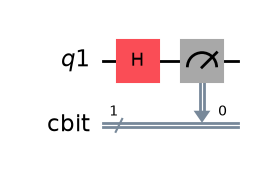

In [6]:
# Apply a hadamard on qubit 0 - this creates equal path case, superposition
# The Hadamard gate can also be expressed as a 90º rotation around the Y-axis, followed by a 180º around the X-axis. 
#
qc.h(0)
# finally perform a measurement
# qubit 0 results stored in classical register 0
qc_measured = qc.measure(0, 0)
# And make a pretty picture of the circuit. - This can be commented out. 
qc.draw(output='mpl')

<b> Run this once per collection of numbers.</b>

In [7]:
def GetRNG(sampler):
    """
    Turning this into a method to get the random numbers. we can call this once in awhile. 
    Tell the sampler how you want to do the program. 
    qc is the quantum circuit
    The following reference has a very good example on how to use this. 
    https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler
    scroll down to the example where the 'pub' is created. 

    pub stands for Primitive unified bloc
    multiple pubs may be submitted. 
    details on pubs - https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output

    details on options - https://quantum.cloud.ibm.com/docs/en/guides/specify-runtime-options

    estimator pubs
    quantum circuit
    A list of one or more observables: [ObservableArrayLike, Pauli, SparsePauliOp, PauliList, str]
    Collection of parameter objects, in this case theta

    Need to introduce the number of shots in this system. 
    
    lets say I want to use this single qubit to generate a series of 16 bit numbers. Then I want the number of shots to 
    be evenly divisable by 16

    @param sampler - the back end to run on. 
    @return xy     - the set of xy numbers.
    """
    # Declare we want 16 bit numbers, we can always change this or make it transparent. 
    BitLength = 16
    # how many numbers do we want in XY as a return? 
    DesiredNumbers = 100
    NShots = DesiredNumbers * BitLength
    # Run the job
    job = sampler.run([qc],shots=NShots)
    # get the results
    result = job.result()[0] # only 1 qubit
    #
    # Now format the resulting qubit data. 
    #
    # get the individual shot data - These are the projected measurements. 
    shot_data = result.data['cbit'].array
    #
    # Reformat the data into a string, numpy call
    #
    div = np.split(shot_data, DesiredNumbers)
    #
    # Create the 16 bit numbers from the bit string. 
    #
    L = len(div)         # length of the bit string
    xy = np.zeros(L)     # create an array to hold the 16 bit numbers. 
    #
    # Need to clean this up. I don't really need the array
    #
    for i in range(L):
        xy[i] = bit2N(div[i])
    return xy

(array([ 8.,  7., 10.,  9.,  8., 12., 10., 11., 14., 11.]),
 array([4.50000e+01, 6.47430e+03, 1.29036e+04, 1.93329e+04, 2.57622e+04,
        3.21915e+04, 3.86208e+04, 4.50501e+04, 5.14794e+04, 5.79087e+04,
        6.43380e+04]),
 <BarContainer object of 10 artists>)

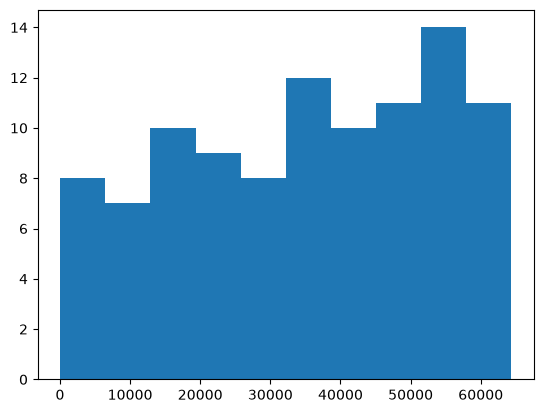

In [10]:
# This is test only and doesn't require to be run except for diagnoistics. 
rn = GetRNG(sampler)
plt.hist(rn)

In [23]:
"""
test out sending to external program here. Loop over 16 bit numbers
Lets make the upper limit 8KHz (2^13) rather than 65535 (2^16)

User changes go here. 
"""

scale = 8192/65536  # how do you want to use these 16 bit numbers? 
#
# Set the outer loop for how many times you want to do this. It is poor use of resources
# to go back to the quantum computer for every single random number, it is better to 
# get a batch at a time. 
#
# the value in the call range sets the number of iterations on the outer loop. 
for i in range(2):
    # Get a batch of random numbers from the QC.
    xy = GetRNG(sampler)
    for val in xy:
        #freq = scale * val
        freq = val%8192
        # send the frequency to oscillator 1 - USER to change here. 
        pOSC.FreqPhase(freq,0.0, 1)
        # Change sleep time as needed. - LONG TERM get a two way conversation between the two processes to make requests
        time.sleep(0.5)
# this is me just setting it to a plesant tone at the end. 
pOSC.FreqPhase(110.0, 0.0, 1)

In [22]:
pOSC.FreqPhase(220.0, 0.0, 2)